In [1]:

# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

# Upload and load Country Schools dataset

from google.colab import files
import pandas as pd
import io

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Dataset loaded successfully!")
print("File:", file_name)
print("Dataset shape:", df.shape)

display(df.head())


Saving Country Schools.csv to Country Schools (1).csv
Dataset loaded successfully!
File: Country Schools (1).csv
Dataset shape: (50, 8)


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34%,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09%,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59%,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93%,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94%,7415.0,286.0,5


In [4]:

# Step 5: Data quality inspection

print("1. Dataset shape:")
print(df.shape)

print("\n2. Missing values:")
print(df.isnull().sum())

print("\n3. Duplicate records:")
print(df.duplicated().sum())

print("\n4. Data types:")
print(df.dtypes)

print("\n5. Statistical summary:")
display(df.describe(include="all"))


1. Dataset shape:
(50, 8)

2. Missing values:
SNO                      2
TOTALSCHOOLS             2
TotalSchoolsInstalled    2
SchoolsPending           2
PercentageInstalled      2
InstalledLDDs            2
InstalledTDDs            2
FID                      0
dtype: int64

3. Duplicate records:
0

4. Data types:
SNO                       object
TOTALSCHOOLS             float64
TotalSchoolsInstalled    float64
SchoolsPending           float64
PercentageInstalled       object
InstalledLDDs            float64
InstalledTDDs            float64
FID                        int64
dtype: object

5. Statistical summary:


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
count,48,48.000000,48.000000,48.000000,48,48.00000,48.000000,50.00000
unique,48,NaN,NaN,NaN,48,NaN,NaN,NaN
top,TURKANA,NaN,NaN,NaN,10.34%,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,1,NaN,NaN,NaN
mean,NaN,905.375000,609.541667,295.833333,NaN,30150.75000,1219.083333,25.50000
std,NaN,3079.865641,2078.968965,1009.291416,NaN,102851.94788,4157.937929,14.57738
min,NaN,93.000000,8.000000,4.000000,NaN,606.00000,16.000000,1.00000
25%,NaN,271.750000,161.250000,53.250000,NaN,6289.00000,322.500000,13.25000
50%,NaN,422.500000,314.500000,130.500000,NaN,14165.00000,629.000000,25.50000
75%,NaN,637.000000,420.250000,247.750000,NaN,23215.00000,840.500000,37.75000


In [5]:

# Step 6: Clean the dataset

clean_df = df.copy()

# Remove percentage symbol and convert to numeric
clean_df["PercentageInstalled"] = (
    clean_df["PercentageInstalled"]
    .astype(str)
    .str.replace("%", "", regex=False)
)

clean_df["PercentageInstalled"] = pd.to_numeric(
    clean_df["PercentageInstalled"],
    errors="coerce"
)

# Convert numerical columns
numeric_columns = [
    "TOTALSCHOOLS",
    "TotalSchoolsInstalled",
    "SchoolsPending",
    "PercentageInstalled",
    "InstalledLDDs",
    "InstalledTDDs"
]

for col in numeric_columns:
    clean_df[col] = pd.to_numeric(clean_df[col], errors="coerce")

# Fill missing numerical values with column medians
clean_df[numeric_columns] = clean_df[numeric_columns].fillna(
    clean_df[numeric_columns].median()
)

print("Preprocessing completed!")

display(clean_df.head())
print("\nMissing values after cleaning:")
print(clean_df.isnull().sum())


Preprocessing completed!


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94,7415.0,286.0,5



Missing values after cleaning:
SNO                      2
TOTALSCHOOLS             0
TotalSchoolsInstalled    0
SchoolsPending           0
PercentageInstalled      0
InstalledLDDs            0
InstalledTDDs            0
FID                      0
dtype: int64


In [6]:

# Handle missing region names
clean_df["SNO"] = clean_df["SNO"].fillna("Unknown")

# Check duplicate records
print("Duplicate records:", clean_df.duplicated().sum())

# Check missing values again
print("\nMissing values:")
print(clean_df.isnull().sum())

print("\nFinal dataset shape:", clean_df.shape)

display(clean_df.head())


Duplicate records: 0

Missing values:
SNO                      0
TOTALSCHOOLS             0
TotalSchoolsInstalled    0
SchoolsPending           0
PercentageInstalled      0
InstalledLDDs            0
InstalledTDDs            0
FID                      0
dtype: int64

Final dataset shape: (50, 8)


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94,7415.0,286.0,5


In [7]:

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

# Select numerical features only
features = [
    "TOTALSCHOOLS",
    "TotalSchoolsInstalled",
    "SchoolsPending",
    "PercentageInstalled",
    "InstalledLDDs",
    "InstalledTDDs"
]

X = clean_df[features]

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Numerical features prepared!")
print("Feature matrix shape:", X_scaled.shape)


Numerical features prepared!
Feature matrix shape: (50, 6)


In [8]:

# Create Isolation Forest model

model = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    random_state=42
)

# Train and predict anomalies
predictions = model.fit_predict(X_scaled)

# Add results to dataset
clean_df["Anomaly"] = predictions

# Convert predictions into readable labels
clean_df["Anomaly_Status"] = clean_df["Anomaly"].map({
    1: "Normal",
    -1: "Anomaly"
})

print("Anomaly detection completed!")

display(
    clean_df[["SNO", "TOTALSCHOOLS",
              "TotalSchoolsInstalled",
              "SchoolsPending",
              "PercentageInstalled",
              "Anomaly_Status"]]
)


Anomaly detection completed!


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,Anomaly_Status
0,TURKANA,358.0,37.0,321.0,10.340,Anomaly
1,HOMA BAY,875.0,552.0,323.0,63.090,Normal
2,WEST POKOT,498.0,242.0,256.0,48.590,Normal
3,KITUI,1238.0,1200.0,38.0,96.930,Anomaly
4,TANA RIVER,159.0,143.0,16.0,89.940,Normal
5,TAITA TAVETA,194.0,172.0,22.0,88.660,Normal
6,UASIN GISHU,456.0,353.0,103.0,77.410,Normal
7,MIGORI,601.0,413.0,188.0,68.720,Normal
8,VIHIGA,378.0,307.0,71.0,81.220,Normal
9,NYAMIRA,406.0,351.0,55.0,86.450,Normal


In [9]:

# Count detected records

print("Anomaly detection results:")

print(clean_df["Anomaly_Status"].value_counts())

normal_count = (clean_df["Anomaly"] == 1).sum()
anomaly_count = (clean_df["Anomaly"] == -1).sum()

print("\nNormal records:", normal_count)
print("Anomalies:", anomaly_count)


Anomaly detection results:
Anomaly_Status
Normal     47
Anomaly     3
Name: count, dtype: int64

Normal records: 47
Anomalies: 3


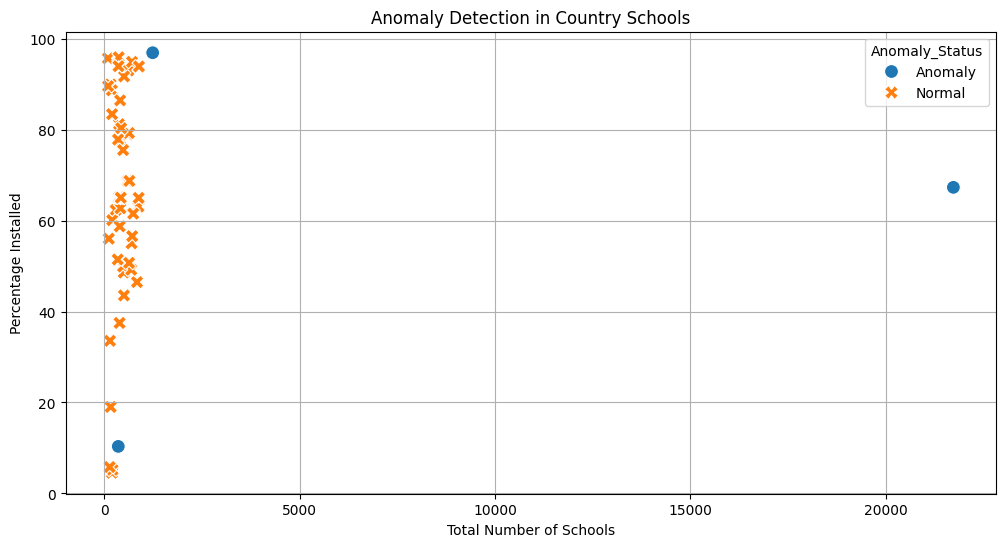

In [10]:

plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=clean_df,
    x="TOTALSCHOOLS",
    y="PercentageInstalled",
    hue="Anomaly_Status",
    style="Anomaly_Status",
    s=100
)

plt.title("Anomaly Detection in Country Schools")
plt.xlabel("Total Number of Schools")
plt.ylabel("Percentage Installed")
plt.grid(True)
plt.show()


In [11]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Select numerical features
cluster_features = [
    "TOTALSCHOOLS",
    "TotalSchoolsInstalled",
    "SchoolsPending",
    "PercentageInstalled",
    "InstalledLDDs",
    "InstalledTDDs"
]

X_cluster = clean_df[cluster_features]

# Standardize features
cluster_scaler = StandardScaler()
X_cluster_scaled = cluster_scaler.fit_transform(X_cluster)

print("Clustering data prepared!")
print("Number of records:", X_cluster_scaled.shape[0])
print("Number of features:", X_cluster_scaled.shape[1])


Clustering data prepared!
Number of records: 50
Number of features: 6


Clusters: 2, Silhouette Score: 0.9060
Clusters: 3, Silhouette Score: 0.5025
Clusters: 4, Silhouette Score: 0.5768
Clusters: 5, Silhouette Score: 0.5137
Clusters: 6, Silhouette Score: 0.4665


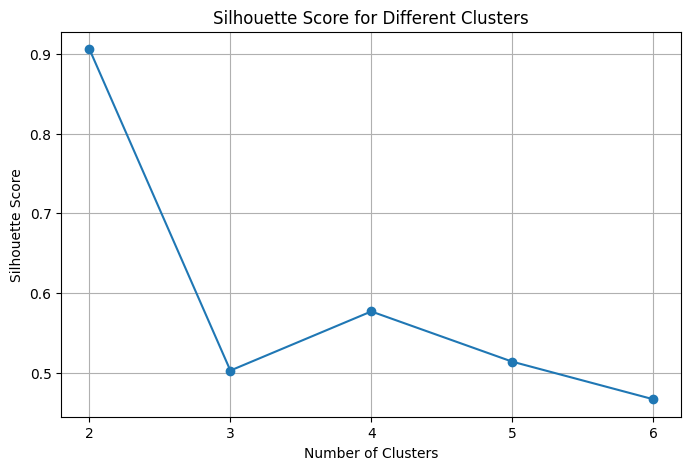

In [12]:

# Test different numbers of clusters

silhouette_scores = []

for k in range(2, 7):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_cluster_scaled)

    score = silhouette_score(X_cluster_scaled, labels)

    silhouette_scores.append(score)

    print(f"Clusters: {k}, Silhouette Score: {score:.4f}")

# Plot silhouette scores
plt.figure(figsize=(8, 5))
plt.plot(range(2, 7), silhouette_scores, marker='o')

plt.title("Silhouette Score for Different Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 7))
plt.grid(True)
plt.show()


In [13]:

# Final K-Means model using 2 clusters

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Train model and assign cluster labels
cluster_labels = kmeans.fit_predict(X_cluster_scaled)

# Add cluster labels to dataset
clean_df["Cluster"] = cluster_labels

print("K-Means clustering completed!")

print("\nNumber of regions in each cluster:")
print(clean_df["Cluster"].value_counts().sort_index())

display(
    clean_df[
        ["SNO", "TOTALSCHOOLS",
         "TotalSchoolsInstalled",
         "SchoolsPending",
         "PercentageInstalled",
         "Cluster"]
    ].head(15)
)


K-Means clustering completed!

Number of regions in each cluster:
Cluster
0    49
1     1
Name: count, dtype: int64


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,Cluster
0,TURKANA,358.0,37.0,321.0,10.34,0
1,HOMA BAY,875.0,552.0,323.0,63.09,0
2,WEST POKOT,498.0,242.0,256.0,48.59,0
3,KITUI,1238.0,1200.0,38.0,96.93,0
4,TANA RIVER,159.0,143.0,16.0,89.94,0
5,TAITA TAVETA,194.0,172.0,22.0,88.66,0
6,UASIN GISHU,456.0,353.0,103.0,77.41,0
7,MIGORI,601.0,413.0,188.0,68.72,0
8,VIHIGA,378.0,307.0,71.0,81.22,0
9,NYAMIRA,406.0,351.0,55.0,86.45,0


In [14]:

# Calculate average characteristics of each cluster

cluster_summary = clean_df.groupby("Cluster")[
    cluster_features
].mean().round(2)

print("Cluster characteristics:")
display(cluster_summary)

print("\nNumber of regions per cluster:")
display(clean_df.groupby("Cluster")["SNO"].count())


Cluster characteristics:


,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs
Cluster,,,,,,
0,460.69,311.39,150.22,63.97,15345.88,622.78
1,21729.00,14629.00,7100.00,67.32,723618.00,29258.00



Number of regions per cluster:


,SNO
Cluster,
0,49
1,1


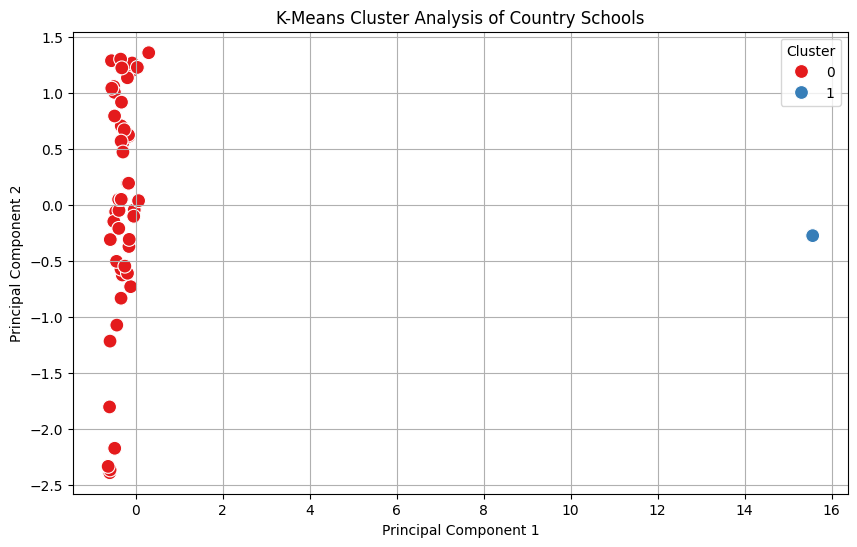

Variance explained by two components: 99.87 %


In [15]:

# Reduce six dimensions to two dimensions

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_cluster_scaled)

# Create visualization dataset
pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": cluster_labels.astype(str),
    "Region": clean_df["SNO"]
})

# Plot clusters
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set1",
    s=100
)

plt.title("K-Means Cluster Analysis of Country Schools")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)
plt.show()

print(
    "Variance explained by two components:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)


In [16]:

# Save processed dataset and experiment results

clean_df.to_csv(
    "Country_Schools_Analysis_Results.csv",
    index=False
)

cluster_summary.to_csv(
    "Country_Schools_Cluster_Summary.csv"
)

print("Results saved successfully!")


Results saved successfully!
